# 01 — Cleaning and EDA

**Question.** How long does a San Francisco emergency ambulance take to travel to the scene, and can we predict it at the moment of dispatch?

**Data source.** SFFD *Fire Department and Emergency Medical Services Dispatched Calls for Service* (DataSF dataset `nuek-vuh3`), 2025 extract stored at `data/raw/nuek-vuh3.csv`. One row per unit response, so several rows can share a `call_number`.

**Target.** `travel_time_s = on_scene_dttm - response_dttm`, in seconds.

**Prediction moment = dispatch.** Features may only use information known at dispatch (no later timestamps, reassessed priorities, call outcomes or `call_type_group`).

All logic lives in `src/`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/; make the project root importable.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from src.load import load_raw
from src.clean import build_ambulance_dataset, apply_rules
from src import plots

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

Matplotlib is building the font cache; this may take a moment.


In [2]:
raw = load_raw()
amb, exclusions = build_ambulance_dataset(raw)  # R6/R7 not chosen yet: min/max = None
engine, _ = apply_rules(raw, {"ENGINE"})        # comparison only, R2-R5
print(f"raw rows: {len(raw):,}   ambulance rows after R1-R5: {len(amb):,}   engine rows after R2-R5: {len(engine):,}")

raw rows: 158,492   ambulance rows after R1-R5: 100,683   engine rows after R2-R5: 52,538


## Exclusion table (R1–R5)

In [3]:
exclusions

,rule,description,rows_before,rows_removed,rows_after,removed_ENGINE,removed_MEDIC,removed_PRIVATE
0,R1,"keep unit_type in ['MEDIC', 'PRIVATE']",158492,54553,103939,54553,0,0
1,R2,"drop missing lat, lon, station_area, or box",103939,4,103935,0,4,0
2,R3,drop travel_time_s <= 0,103935,3201,100734,0,1577,1624
3,R4,drop dispatch < received or response < dispatch,100734,16,100718,0,6,10
4,R5,"drop [received, on_scene] overlapping a 2025 D...",100718,35,100683,0,28,7


## Travel time distribution (ambulances)

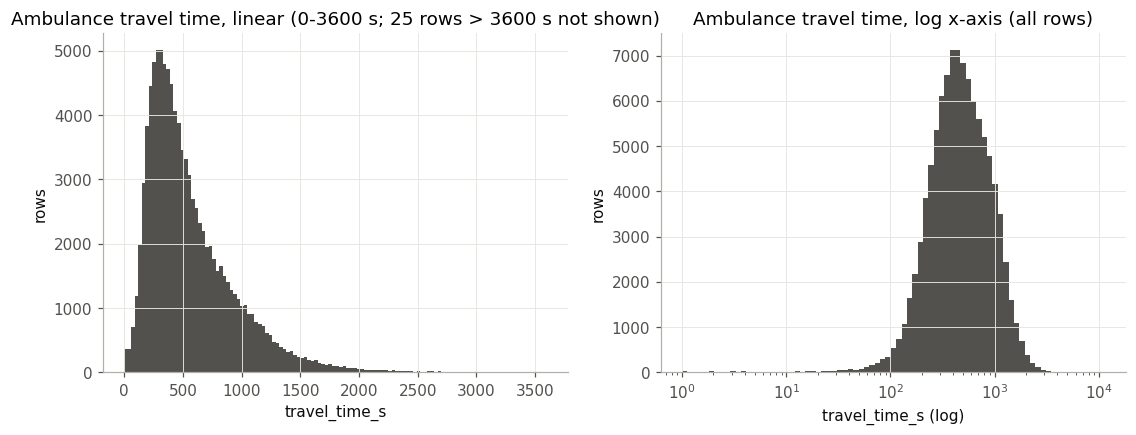

In [4]:
plots.travel_time_hist(amb);

## Travel time density: MEDIC vs PRIVATE vs ENGINE

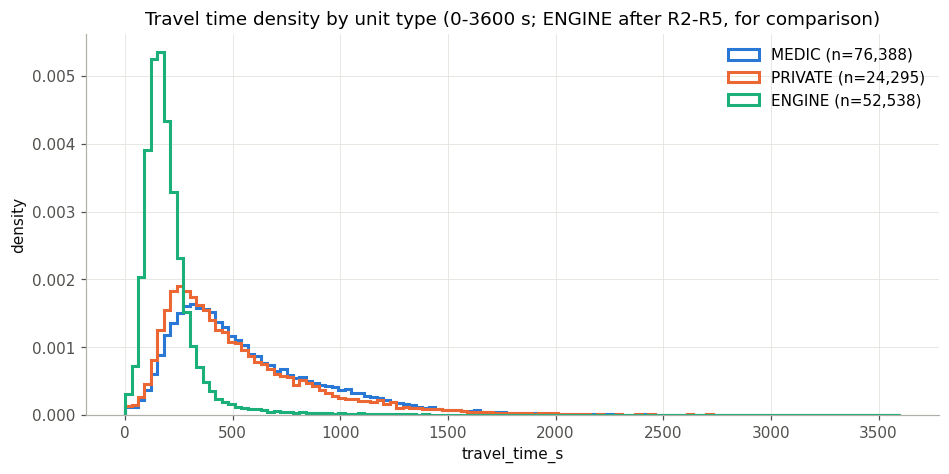

In [5]:
plots.travel_time_density_by_unit(amb, engine);

## Median travel time by hour of day

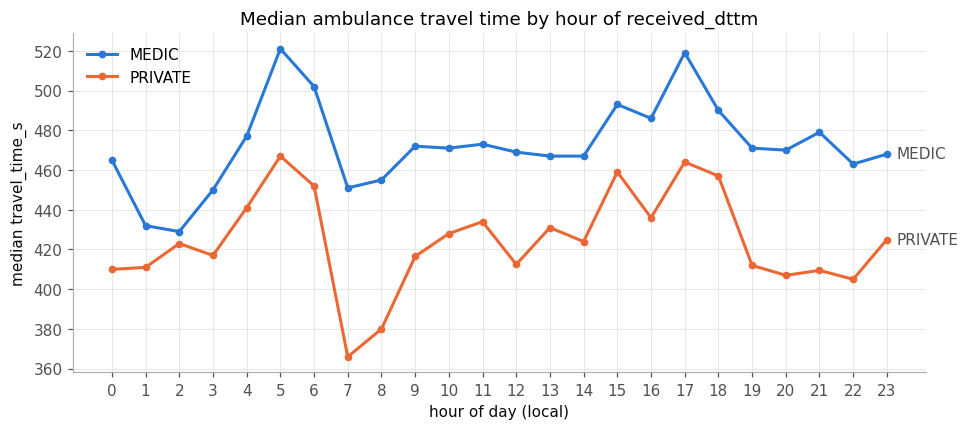

In [6]:
plots.median_by_hour(amb);

## Travel time by original priority

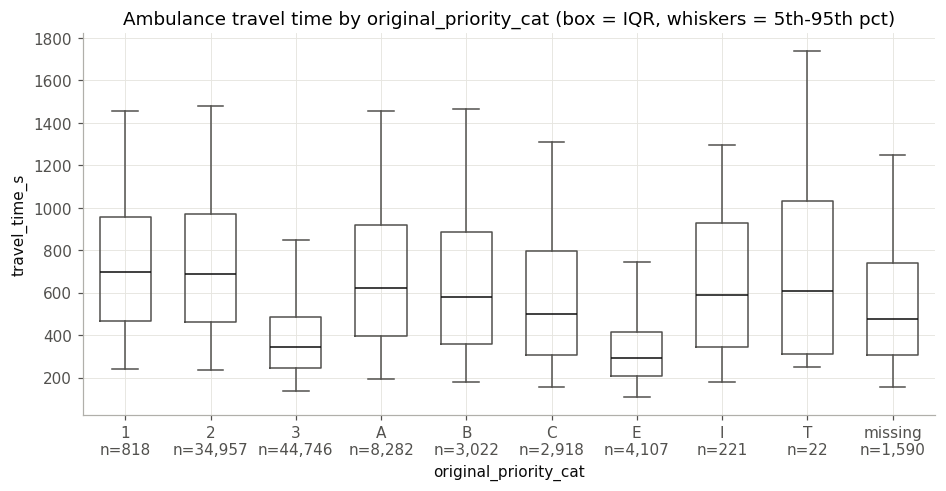

In [7]:
plots.boxplot_by_priority(amb);

## Median travel time per box (map)

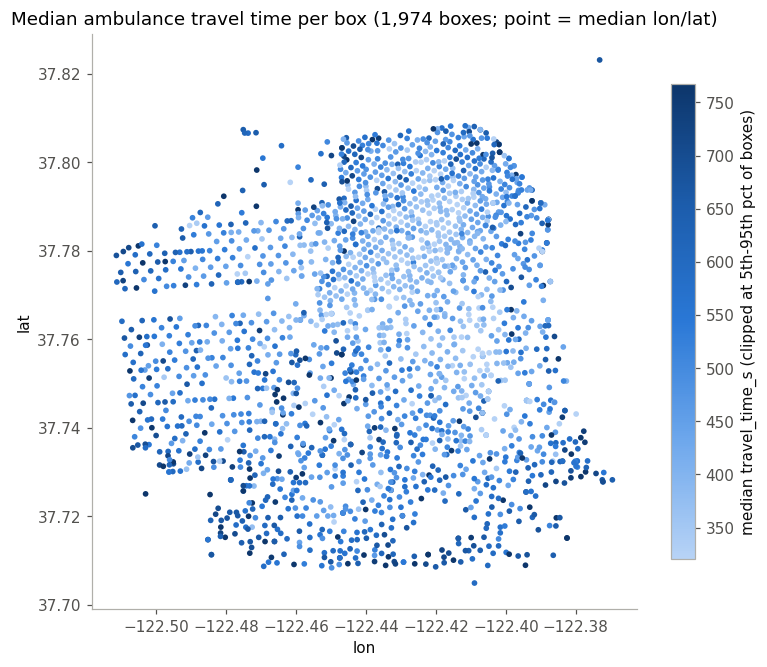

In [8]:
plots.box_median_map(amb);

## Decision R6

## Decision R7